In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
 df = pd.read_csv(r"../../Dataset/NF-ToN-IoT-v2.csv", low_memory=False)

In [3]:
df.head(5)

,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,...,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,Label,Attack
0,192.168.1.193,49235,192.168.1.33,4444,6,0.0,155392,202,34552,149,...,45555,4805,0,0,0,0,0,0,1,ransomware
1,192.168.1.193,49228,192.168.1.152,1880,6,0.0,1600,40,35741,65,...,16425,237,0,0,0,0,0,0,0,Benign
2,192.168.1.152,0,192.168.1.193,0,1,0.0,212,2,0,0,...,0,0,771,3,0,0,0,0,0,Benign
3,192.168.1.169,65317,239.255.255.250,1900,17,0.0,165,1,0,0,...,0,0,0,0,0,0,0,0,0,Benign
4,192.168.1.79,60766,192.168.1.255,15600,17,0.0,63,1,0,0,...,0,0,0,0,0,0,0,0,0,Benign


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16940496 entries, 0 to 16940495
Data columns (total 45 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   IPV4_SRC_ADDR                object 
 1   L4_SRC_PORT                  int64  
 2   IPV4_DST_ADDR                object 
 3   L4_DST_PORT                  int64  
 4   PROTOCOL                     int64  
 5   L7_PROTO                     float64
 6   IN_BYTES                     int64  
 7   IN_PKTS                      int64  
 8   OUT_BYTES                    int64  
 9   OUT_PKTS                     int64  
 10  TCP_FLAGS                    int64  
 11  CLIENT_TCP_FLAGS             int64  
 12  SERVER_TCP_FLAGS             int64  
 13  FLOW_DURATION_MILLISECONDS   int64  
 14  DURATION_IN                  int64  
 15  DURATION_OUT                 int64  
 16  MIN_TTL                      int64  
 17  MAX_TTL                      int64  
 18  LONGEST_FLOW_PKT             int64  
 19

In [5]:
df.shape

(16940496, 45)

In [6]:
df.isnull().sum()

IPV4_SRC_ADDR                  0
L4_SRC_PORT                    0
IPV4_DST_ADDR                  0
L4_DST_PORT                    0
PROTOCOL                       0
L7_PROTO                       0
IN_BYTES                       0
IN_PKTS                        0
OUT_BYTES                      0
OUT_PKTS                       0
TCP_FLAGS                      0
CLIENT_TCP_FLAGS               0
SERVER_TCP_FLAGS               0
FLOW_DURATION_MILLISECONDS     0
DURATION_IN                    0
DURATION_OUT                   0
MIN_TTL                        0
MAX_TTL                        0
LONGEST_FLOW_PKT               0
SHORTEST_FLOW_PKT              0
MIN_IP_PKT_LEN                 0
MAX_IP_PKT_LEN                 0
SRC_TO_DST_SECOND_BYTES        0
DST_TO_SRC_SECOND_BYTES        0
RETRANSMITTED_IN_BYTES         0
RETRANSMITTED_IN_PKTS          0
RETRANSMITTED_OUT_BYTES        0
RETRANSMITTED_OUT_PKTS         0
SRC_TO_DST_AVG_THROUGHPUT      0
DST_TO_SRC_AVG_THROUGHPUT      0
NUM_PKTS_U

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.describe()

/data/aicoe_gpu/sayantan_singha_roy_ek3/fl-ids/.venv/lib/python3.12/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: overflow encountered in square
  sqr = _ensure_numeric((avg - values) ** 2)
/data/aicoe_gpu/sayantan_singha_roy_ek3/fl-ids/.venv/lib/python3.12/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: overflow encountered in square
  sqr = _ensure_numeric((avg - values) ** 2)


,L4_SRC_PORT,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,TCP_FLAGS,CLIENT_TCP_FLAGS,...,NUM_PKTS_1024_TO_1514_BYTES,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,Label
count,1.694050e+07,1.694050e+07,1.694050e+07,1.694050e+07,1.694050e+07,1.694050e+07,1.694050e+07,1.694050e+07,1.694050e+07,1.694050e+07,...,1.694050e+07,1.694050e+07,1.694050e+07,1.694050e+07,1.694050e+07,1.694050e+07,1.694050e+07,1.694050e+07,1.694050e+07,1.694050e+07
mean,4.335412e+04,9.282269e+03,7.615534e+00,1.377321e+01,7.263503e+02,6.359542e+00,8.366019e+02,3.216062e+00,1.279886e+01,9.489224e+00,...,5.070125e-01,1.064363e+04,1.036421e+04,4.255479e+02,1.662295e+00,4.659713e+03,1.544335e+00,4.119134e+03,1.473166e+00,6.399474e-01
std,1.517270e+04,1.685280e+04,3.925834e+00,3.202067e+01,1.433178e+05,5.091666e+02,1.017853e+05,2.580863e+02,1.128540e+01,1.091408e+01,...,1.057214e+02,1.354493e+04,1.801608e+04,4.087310e+03,1.596605e+01,1.350202e+04,8.668465e+00,4.734344e+04,2.579710e+01,4.800153e-01
min,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,4.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.732400e+04,8.000000e+01,6.000000e+00,0.000000e+00,4.400000e+01,1.000000e+00,0.000000e+00,0.000000e+00,2.000000e+00,2.000000e+00,...,0.000000e+00,1.024000e+03,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,4.577000e+04,4.430000e+02,6.000000e+00,0.000000e+00,5.200000e+01,1.000000e+00,4.000000e+01,1.000000e+00,1.700000e+01,2.000000e+00,...,0.000000e+00,1.024000e+03,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
75%,5.421800e+04,8.080000e+03,6.000000e+00,7.000000e+00,2.760000e+02,4.000000e+00,1.800000e+02,3.000000e+00,2.200000e+01,1.800000e+01,...,0.000000e+00,2.920000e+04,2.896000e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
max,6.553500e+04,6.553500e+04,5.800000e+01,2.480000e+02,3.019262e+08,4.692810e+05,1.644688e+08,4.109030e+05,2.230000e+02,2.230000e+02,...,2.009840e+05,6.553500e+04,6.553500e+04,6.528600e+04,2.550000e+02,6.553500e+04,2.550000e+02,6.048000e+06,5.530000e+02,1.000000e+00


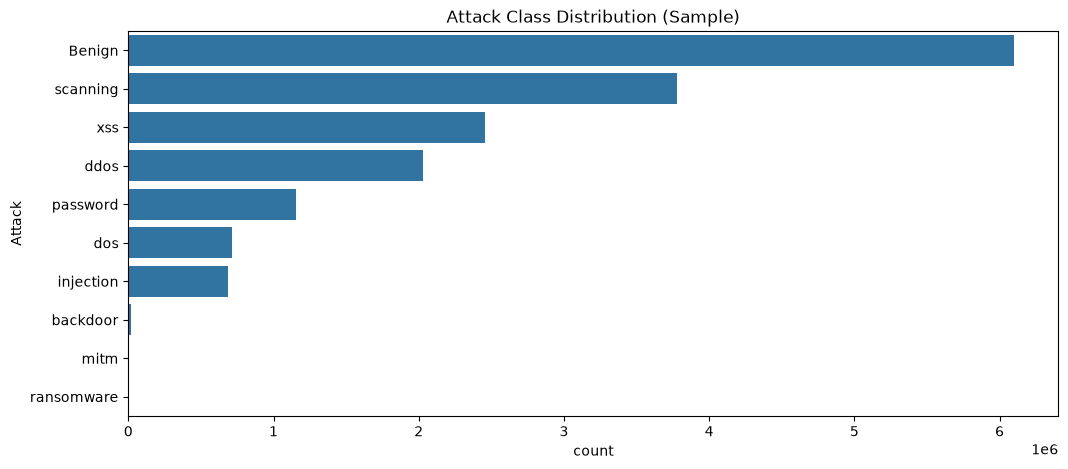

Attack
Benign        36.01
scanning      22.32
xss           14.49
ddos          11.96
password       6.81
dos            4.21
injection      4.04
backdoor       0.10
mitm           0.05
ransomware     0.02
Name: proportion, dtype: float64


In [9]:

plt.figure(figsize=(12,5))
order = df["Attack"].value_counts().index
sns.countplot(data=df, y="Attack", order=order)
plt.title("Attack Class Distribution (Sample)")
plt.show()

print(df["Attack"].value_counts(normalize=True).mul(100).round(2))

In [10]:
## corelation heatmap

In [11]:

# 1. Downcast integers one column at a time (In-place)
for col in df.select_dtypes(include=['int64']).columns:
    df[col] = pd.to_numeric(df[col], downcast='integer')

# 2. Downcast floats one column at a time (In-place)
for col in df.select_dtypes(include=['float64']).columns:
    df[col] = pd.to_numeric(df[col], downcast='float')

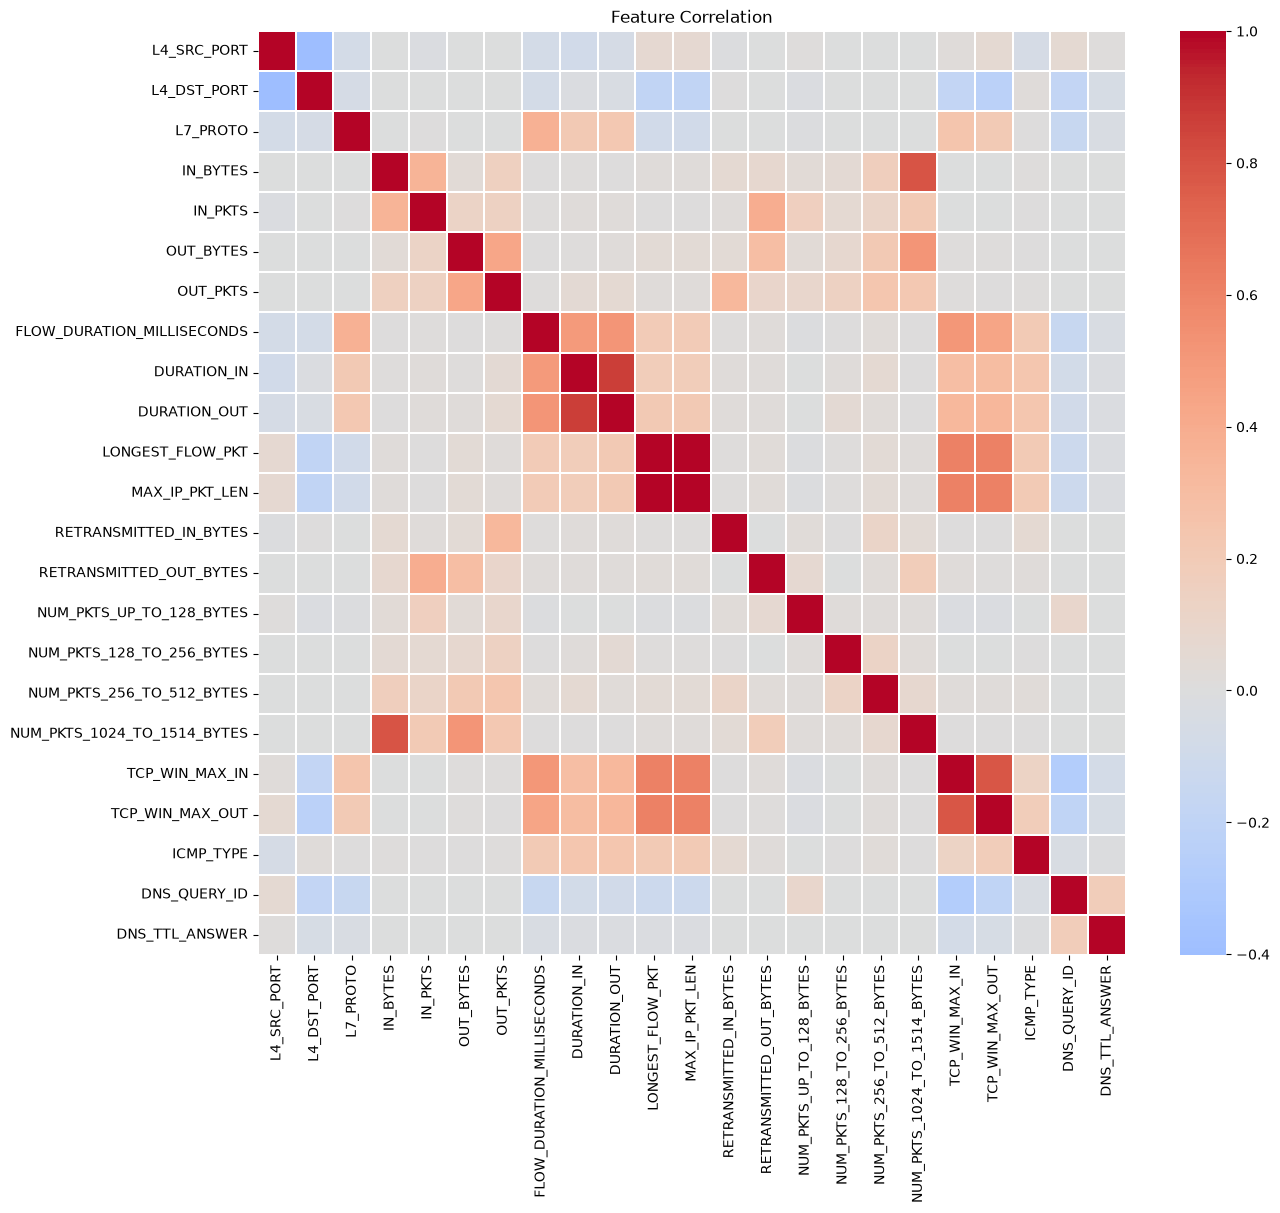

In [12]:
num_cols = df.select_dtypes(include=["int32","float32"]).columns.tolist()
# remove Label if present
corr = df[num_cols].corr()

plt.figure(figsize=(14,12))
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.3)
plt.title("Feature Correlation")
plt.show()

In [13]:

df["Label"]

0           1
1           0
2           0
3           0
4           0
           ..
16940491    0
16940492    0
16940493    0
16940494    0
16940495    0
Name: Label, Length: 16940496, dtype: int8

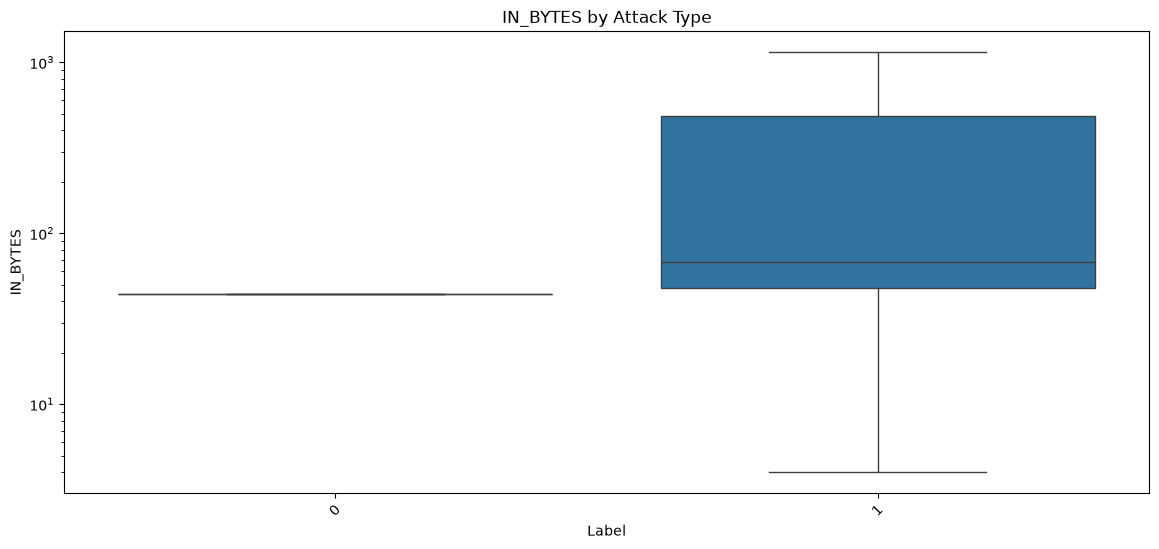

In [14]:
plt.figure(figsize=(14,6))
sns.boxplot(data=df, x="Label", y="IN_BYTES", showfliers=False)
plt.xticks(rotation=45)
plt.yscale("log")
plt.title("IN_BYTES by Attack Type")
plt.show()

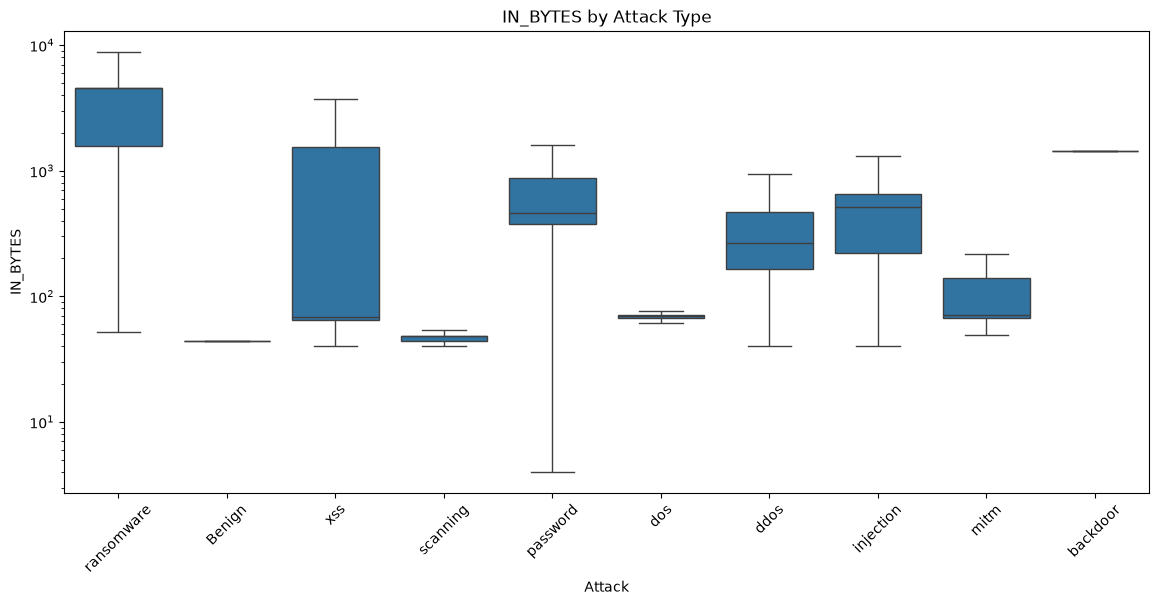

In [15]:
plt.figure(figsize=(14,6))
sns.boxplot(data=df, x="Attack", y="IN_BYTES", showfliers=False)
plt.xticks(rotation=45)
plt.yscale("log")
plt.title("IN_BYTES by Attack Type")
plt.show()

In [16]:
drop_cols = [
    'IPV4_SRC_ADDR', 'IPV4_DST_ADDR',
    'L4_SRC_PORT',
    'DNS_QUERY_ID'         # keep 'Label' as binary target
]
# Optionally also:
# drop_cols += ['L4_DST_PORT']          # if you don't bin it
# drop_cols += ['CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS']  # if corr with TCP_FLAGS > 0.95

df.drop(columns=drop_cols,inplace=True)
# y = df['Label']   # binary 0/1 target

In [17]:
df.shape

(16940496, 41)

In [18]:
# 1. Near-zero-variance columns (e.g., a column that's 99.9% one value)
from sklearn.feature_selection import VarianceThreshold
near_zero = [c for c in df.columns if df[c].value_counts(normalize=True).iloc[0] > 0.999]

# 2. Highly correlated pairs (|r| > 0.95) — keep one
corr = df.select_dtypes('number').corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr_drop = [c for c in upper.columns if any(upper[c] > 0.95)]

# 3. All-NaN or all-zero columns
all_zero_or_nan = [c for c in df.columns if (df[c].fillna(-1) == df[c].iloc[0]).all()]

In [19]:
# 1. Select only numeric columns (correlation requires numbers)
numeric_df = df.select_dtypes(include=['number'])

# 2. Calculate correlation of all numeric columns with 'Label'
# We drop 'Label' itself from the result to avoid a perfect 1.0 correlation
corr_with_label = numeric_df.corr()['Label'].drop('Label')

# 3. Sort by absolute value to see the strongest relationships first
sorted_corr = corr_with_label.abs().sort_values(ascending=False)

print("--- Correlation of Features with 'Label' ---")
print(sorted_corr)

--- Correlation of Features with 'Label' ---
TCP_WIN_MAX_IN                 0.358672
CLIENT_TCP_FLAGS               0.340318
MIN_IP_PKT_LEN                 0.326147
TCP_WIN_MAX_OUT                0.315930
MIN_TTL                        0.286961
MAX_TTL                        0.285889
LONGEST_FLOW_PKT               0.252001
MAX_IP_PKT_LEN                 0.252001
SERVER_TCP_FLAGS               0.219127
FLOW_DURATION_MILLISECONDS     0.201247
TCP_FLAGS                      0.201004
PROTOCOL                       0.123348
DNS_TTL_ANSWER                 0.111837
L4_DST_PORT                    0.106477
DURATION_OUT                   0.102323
SRC_TO_DST_AVG_THROUGHPUT      0.091341
L7_PROTO                       0.089257
DURATION_IN                    0.069607
SHORTEST_FLOW_PKT              0.069592
DST_TO_SRC_AVG_THROUGHPUT      0.057341
DNS_QUERY_TYPE                 0.050021
FTP_COMMAND_RET_CODE           0.038322
NUM_PKTS_UP_TO_128_BYTES       0.034400
RETRANSMITTED_OUT_PKTS         0.02

In [20]:
# Check the direct correlation between the two columns
ttl_correlation = df['MIN_TTL'].corr(df['MAX_TTL'])
print(f"Correlation between MIN_TTL and MAX_TTL: {ttl_correlation:.4f}")


Correlation between MIN_TTL and MAX_TTL: 0.9995


In [ ]:
# Check if every single row matches perfectly
are_ttl_identical = df['MIN_TTL'].equals(df['MAX_TTL'])
print(f"Are MIN_TTL and MAX_TTL exact duplicates? {are_ttl_identical}")

# Count exactly how many rows are different
ttl_differences = (df['MIN_TTL'] != df['MAX_TTL']).sum()
print(f"Number of rows where they differ: {ttl_differences} out of {len(df)}")

# Check their average difference to see how close they are
avg_diff = (df['MAX_TTL'] - df['MIN_TTL']).abs().mean()
print(f"Average absolute difference between them: {avg_diff:.4f}")


In [21]:
# Columns proven to be redundant or useless based on your correlation output
cols_to_drop_now = [
    'MAX_IP_PKT_LEN',          # Exact duplicate of LONGEST_FLOW_PKT
    'ICMP_IPV4_TYPE',  
    'OUT_PKTS',                         # Near-exact duplicate of ICMP_TYPE
    'SRC_TO_DST_SECOND_BYTES', # 0.000000 correlation
    'DST_TO_SRC_SECOND_BYTES'  # 0.000000 correlation
]

# Drop them in-place to save memory
df.drop(columns=cols_to_drop_now, inplace=True, errors='ignore')

print(f"Successfully dropped {len(cols_to_drop_now)} redundant columns.")
print(f"Remaining columns: {len(df.columns)}")

Successfully dropped 5 redundant columns.
Remaining columns: 36


In [22]:
# 1. Isolate numeric columns
numeric_cols = df.select_dtypes(include=['number']).columns

# 2. Calculate skewness (Pandas handles this efficiently even on large datasets)
skewness_values = df[numeric_cols].skew().sort_values(ascending=False)

# 3. Display as a clean DataFrame
skew_df = pd.DataFrame({'Column': skewness_values.index, 'Skewness': skewness_values.values})
print("--- Skewness of All Numeric Columns ---")
print(skew_df.to_string(index=False))

--- Skewness of All Numeric Columns ---
                     Column    Skewness
      RETRANSMITTED_IN_PKTS 2178.900287
     RETRANSMITTED_IN_BYTES 2059.182443
                   IN_BYTES 1636.614492
NUM_PKTS_1024_TO_1514_BYTES 1393.727775
                  OUT_BYTES  980.684959
    RETRANSMITTED_OUT_BYTES  975.930048
  NUM_PKTS_256_TO_512_BYTES  922.687879
  NUM_PKTS_128_TO_256_BYTES  866.499220
     RETRANSMITTED_OUT_PKTS  740.255140
 NUM_PKTS_512_TO_1024_BYTES  645.864186
                    IN_PKTS  537.719650
                DURATION_IN  194.678917
               DURATION_OUT  185.891255
  DST_TO_SRC_AVG_THROUGHPUT  106.646264
  SRC_TO_DST_AVG_THROUGHPUT   80.440105
   NUM_PKTS_UP_TO_128_BYTES   44.521131
          SHORTEST_FLOW_PKT   22.221993
       FTP_COMMAND_RET_CODE   18.285716
             DNS_QUERY_TYPE   17.271272
             DNS_TTL_ANSWER   12.727926
                  ICMP_TYPE   10.932826
           LONGEST_FLOW_PKT    5.131986
                   L7_PROTO    2.636717


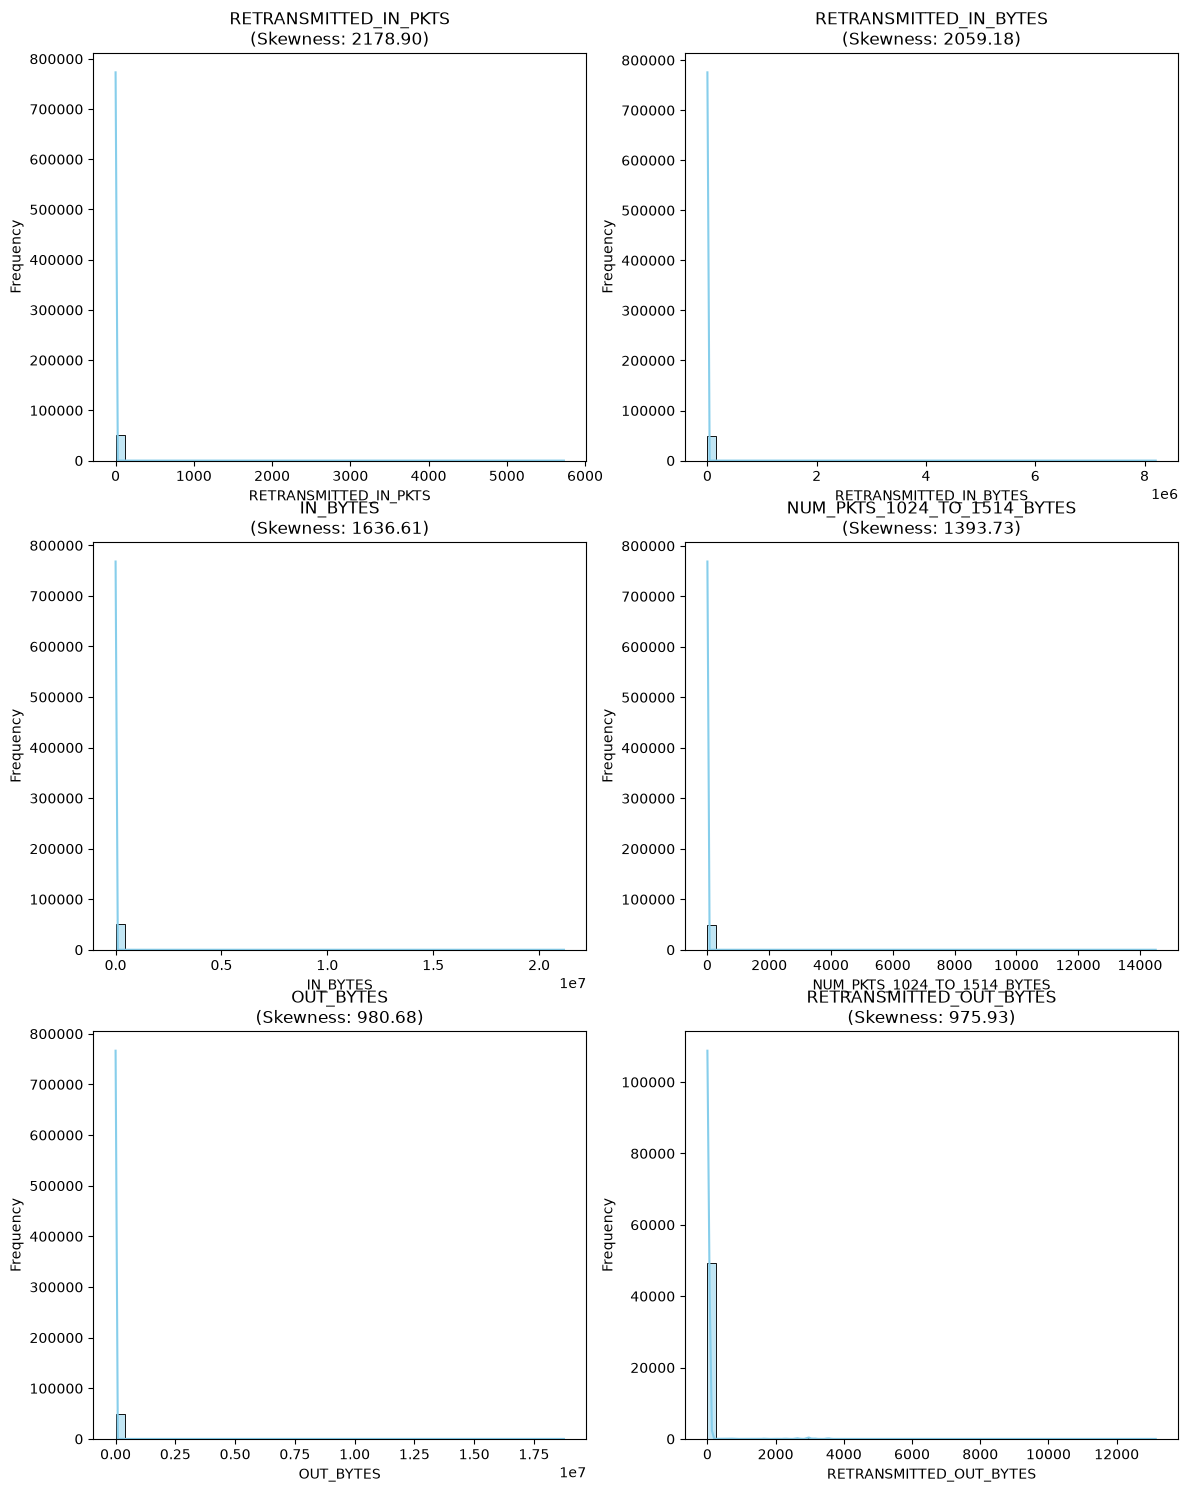

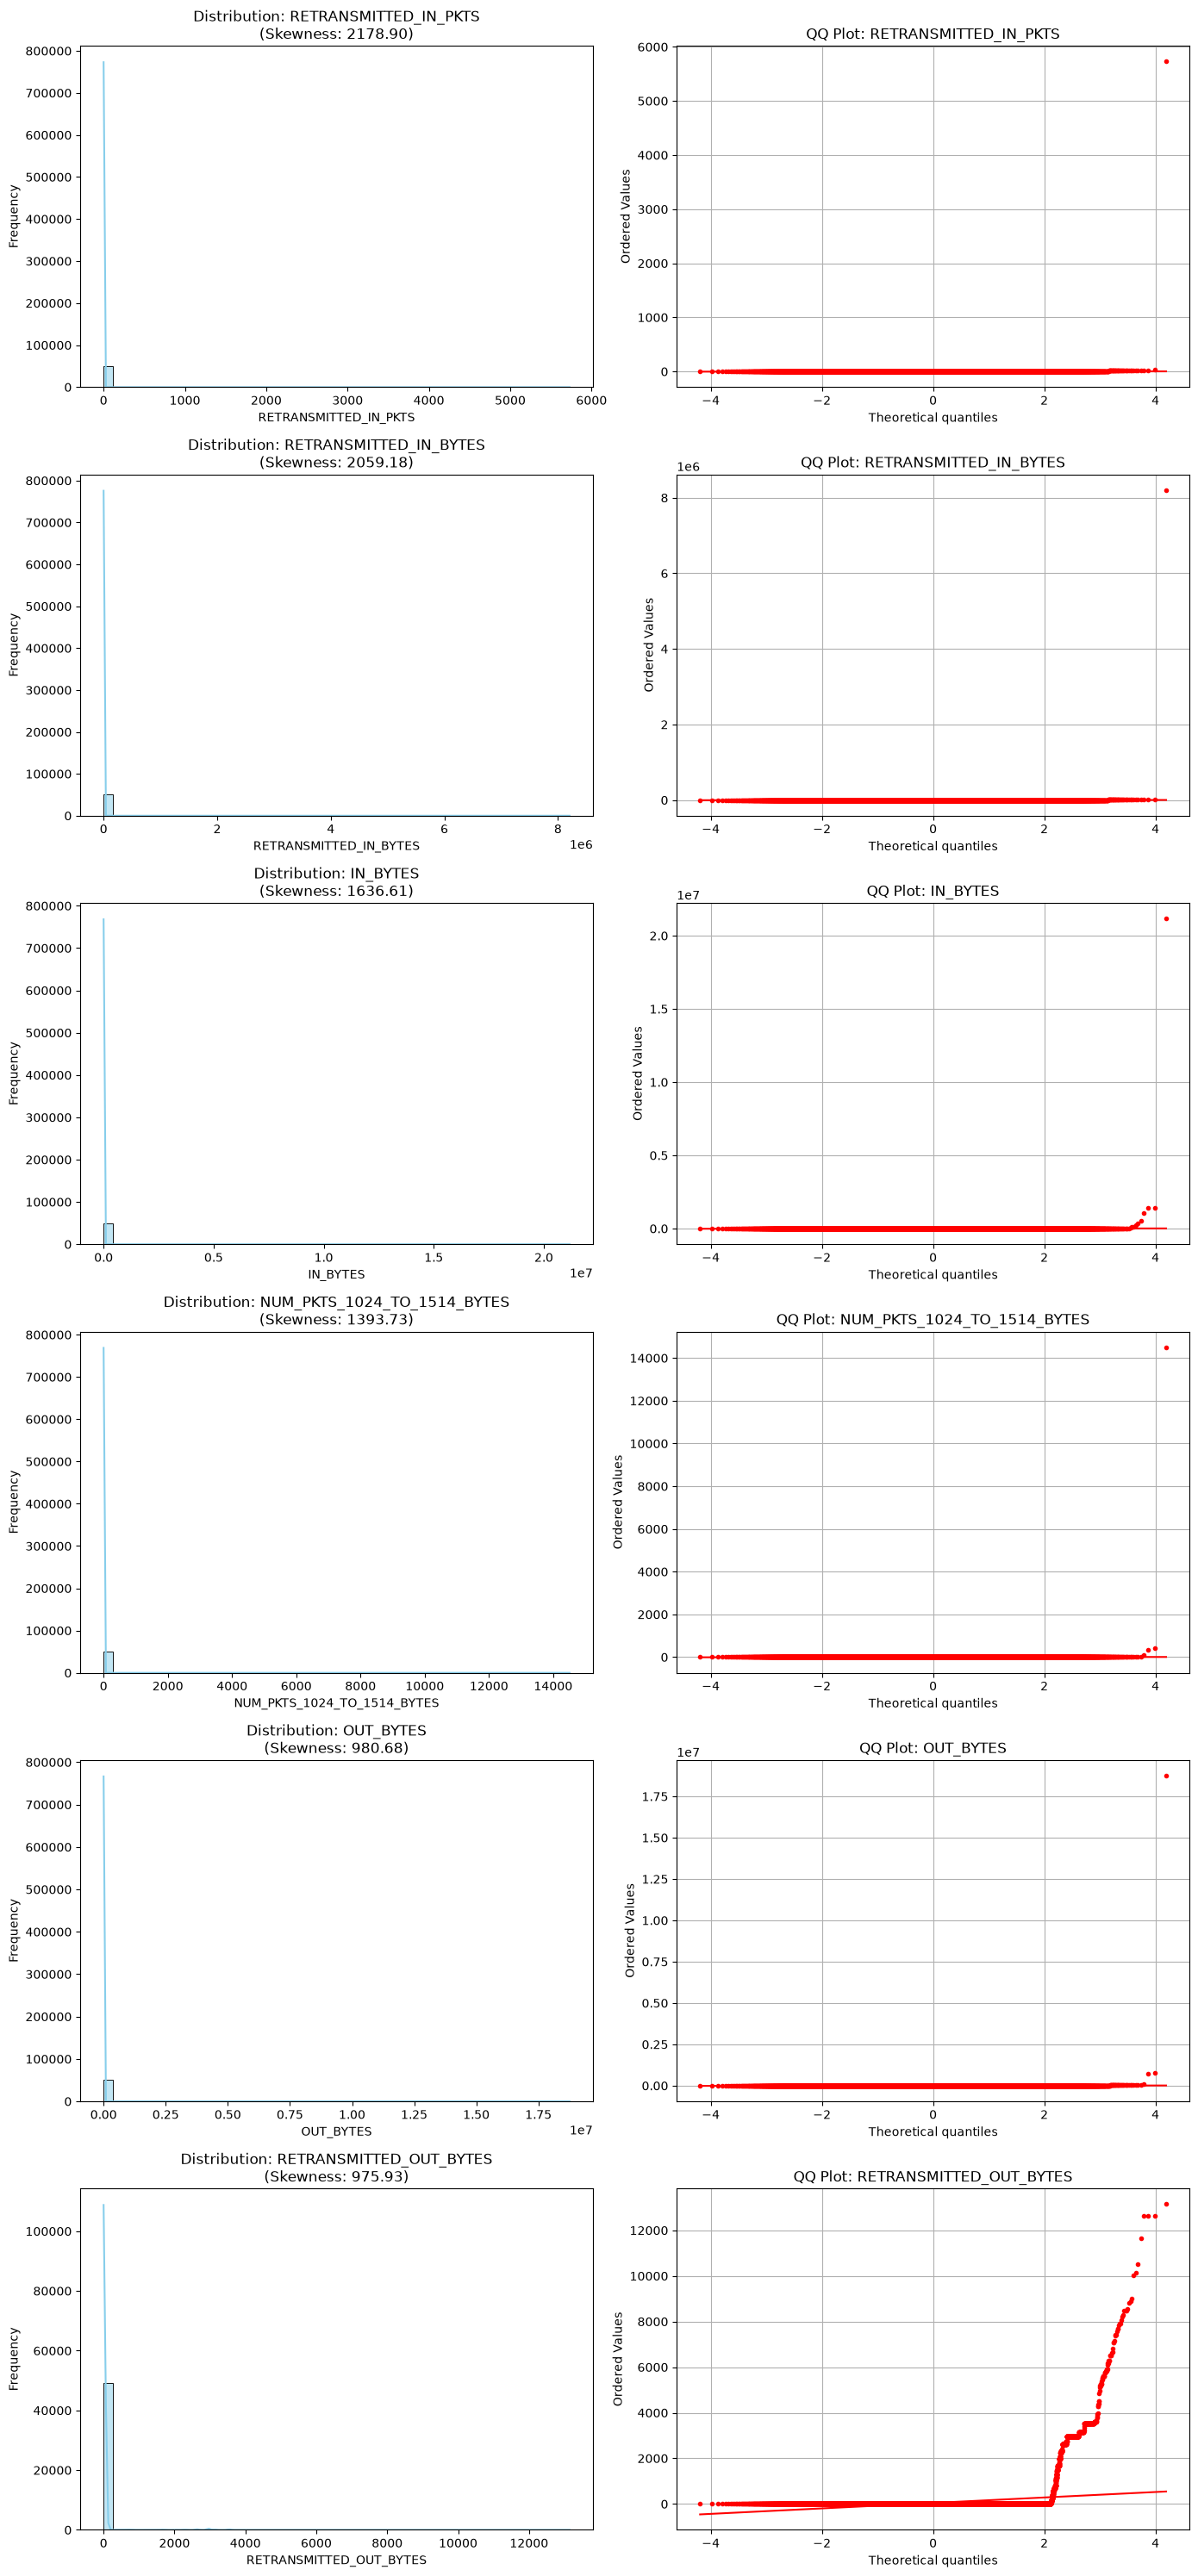

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore') # Suppress minor scipy warnings for extreme values

# 1. Take a representative sample for plotting (50,000 rows is plenty for shape analysis)
# This prevents your RAM from maxing out and crashing the kernel
sample_size = 50000
sample_df = df[numeric_cols].sample(n=sample_size, random_state=42)

# 2. Select the top 6 most skewed columns to visualize
top_skewed_cols = skewness_values.abs().sort_values(ascending=False).head(6).index.tolist()

# 3. Setup the plot grid (2 columns, 3 rows)
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(14, 18))
axes = axes.flatten()

for i, col in enumerate(top_skewed_cols):
    ax_hist = axes[i]
    
    # --- Left side: Histogram with KDE ---
    sns.histplot(sample_df[col], kde=True, ax=ax_hist, color='skyblue', bins=50)
    ax_hist.set_title(f'{col}\n(Skewness: {skewness_values[col]:.2f})')
    ax_hist.set_xlabel(col)
    ax_hist.set_ylabel('Frequency')
    
    # --- Right side: QQ Plot ---
    # We create a subplot grid inside the main axis to hold the QQ plot neatly
    # Or simpler: just use scipy's probplot directly on a new figure, but let's keep it clean.
    # Actually, scipy's probplot is easiest to read in its own dedicated layout.
    
# Let's refine the layout: 1 row per column, 2 subplots (Hist + QQ)
fig, axes = plt.subplots(nrows=len(top_skewed_cols), ncols=2, figsize=(14, 5 * len(top_skewed_cols)))

# Handle case where there's only 1 column (axes won't be 2D)
if len(top_skewed_cols) == 1:
    axes = np.array([axes])

for i, col in enumerate(top_skewed_cols):
    # 1. Histogram
    sns.histplot(sample_df[col], kde=True, ax=axes[i, 0], color='skyblue', bins=50)
    axes[i, 0].set_title(f'Distribution: {col}\n(Skewness: {skewness_values[col]:.2f})')
    axes[i, 0].set_xlabel(col)
    axes[i, 0].set_ylabel('Frequency')
    
    # 2. QQ Plot
    # Drop NaNs/Infs for the QQ plot to prevent scipy from crashing
    clean_data = sample_df[col].dropna()
    clean_data = clean_data[np.isfinite(clean_data)]
    
    stats.probplot(clean_data, dist="norm", plot=axes[i, 1])
    axes[i, 1].get_lines()[0].set_marker('.') # Make points smaller for 50k rows
    axes[i, 1].get_lines()[0].set_markerfacecolor('red')
    axes[i, 1].get_lines()[0].set_markeredgecolor('red')
    axes[i, 1].set_title(f'QQ Plot: {col}')
    axes[i, 1].grid(True)

plt.tight_layout()
plt.show()

In [24]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import RobustScaler

# Select numeric columns except the target column
numeric_cols = df.select_dtypes(include=np.number).columns.drop(
    "Label", errors="ignore"
)

# Log transformation: requires non-negative values
if (df[numeric_cols] < 0).any().any():
    raise ValueError("Negative values found. log1p cannot be applied safely.")

df[numeric_cols] = np.log1p(df[numeric_cols])

# Robust scaling
scaler = RobustScaler()
df[numeric_cols] = scaler.fit_transform(df[numeric_cols])

print("Transformation and RobustScaler applied successfully.")
print(df.head())

Transformation and RobustScaler applied successfully.
   L4_DST_PORT  PROTOCOL  L7_PROTO  IN_BYTES   IN_PKTS  OUT_BYTES  TCP_FLAGS  \
0     0.500500  0.000000       0.0  4.392879  5.042132   1.295889   0.161278   
1     0.313663  0.000000       0.0  1.875303  3.296361   1.302398   0.161278   
2    -1.324367 -1.252930       0.0  0.765398  0.442507  -0.714355  -1.419018   
3     0.315961  0.944336       0.0  0.628218  0.000000  -0.714355  -1.419018   
4     0.773279  0.944336       0.0  0.103772  0.000000  -0.714355  -1.419018   

   CLIENT_TCP_FLAGS  SERVER_TCP_FLAGS  FLOW_DURATION_MILLISECONDS  ...  \
0          1.148680          1.057268                   15.272951  ...   
1          0.939742          1.057268                   15.272951  ...   
2         -0.595187          0.000000                    0.000000  ...   
3         -0.595187          0.000000                    0.000000  ...   
4         -0.595187          0.000000                    0.000000  ...   

   NUM_PKTS_512_TO_1

In [25]:
df['Label']

0           1
1           0
2           0
3           0
4           0
           ..
16940491    0
16940492    0
16940493    0
16940494    0
16940495    0
Name: Label, Length: 16940496, dtype: int8

In [26]:
df['Attack']

0           ransomware
1               Benign
2               Benign
3               Benign
4               Benign
               ...    
16940491        Benign
16940492        Benign
16940493        Benign
16940494        Benign
16940495        Benign
Name: Attack, Length: 16940496, dtype: object

In [27]:
# Count occurrences of 0 and 1 in Label
print(df["Label"].value_counts().reindex([0, 1], fill_value=0))

# Count and percentage
print("\nLabel distribution:")
print(df["Label"].value_counts(normalize=False).reindex([0, 1], fill_value=0))

print("\nPercentage distribution:")
print(
    (df["Label"].value_counts(normalize=True) * 100)
    .reindex([0, 1], fill_value=0)
    .round(2)
)

Label
0     6099469
1    10841027
Name: count, dtype: int64

Label distribution:
Label
0     6099469
1    10841027
Name: count, dtype: int64

Percentage distribution:
Label
0    36.01
1    63.99
Name: proportion, dtype: float64


In [28]:
import numpy as np

# Select only numeric columns, then count total infinite values
np.isinf(df.select_dtypes(include=[np.number])).values.sum()


np.int64(0)

In [29]:

# If you still have the raw df with string Attack labels:
counts = df['Attack'].value_counts()
print(counts)

Attack
Benign        6099469
scanning      3781419
xss           2455020
ddos          2026234
password      1153323
dos            712609
injection      684465
backdoor        16809
mitm             7723
ransomware       3425
Name: count, dtype: int64


In [30]:
uv add ctgan

Resolved 178 packages in 1ms
Checked 175 packages in 1ms
Note: you may need to restart the kernel to use updated packages.


In [31]:
# Drop a single column, in-place
df.drop(columns=['Label'], inplace=True)


In [32]:
df.shape

(16940496, 35)

In [33]:
uv add imbalanced-learn

Resolved 178 packages in 1ms
Checked 175 packages in 1ms
Note: you may need to restart the kernel to use updated packages.


In [39]:

# from imblearn.over_sampling import SMOTE

# # 1. Separate features and target
# X = df.drop(columns=["Attack"], errors="ignore")
# y = df["Attack"]

# # 2. Configure SMOTE to bring minority classes to 30,000
# target_count = 400000

# current_counts = y.value_counts()
# sampling_strategy = {
#     attack: target_count
#     for attack, count in current_counts.items()
#     if count < target_count
# }

# # 3. Generate synthetic samples
# smote = SMOTE(
#     sampling_strategy=sampling_strategy,
#     random_state=42,
#     k_neighbors=5
# )

# X_resampled, y_resampled = smote.fit_resample(X, y)

# # 4. Reconstruct the resulting dataset
# df_resampled = pd.DataFrame(
#     X_resampled,
#     columns=X.columns
# )
# df_resampled["Attack"] = y_resampled

# # 5. Save the final dataset
# df_resampled.to_csv("ToN-IoT_SMOTE.csv", index=False)

# # 6. Verify counts and output
# print(df_resampled["Attack"].value_counts())
# print("Final shape:", df_resampled.shape)
# print("Saved: ToN-IoT_SMOTE.csv")

Attack
Benign        4879575
scanning      3781419
xss           2455020
ddos          2026234
password      1153323
dos            712609
injection      684465
backdoor       400000
mitm           400000
ransomware     400000
Name: count, dtype: int64
Final shape: (16892645, 35)
Saved: ToN-IoT_SMOTE.csv


In [48]:

import pandas as pd
import numpy as np

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

# ============================================================
# STEP 1: Separate features and multiclass target
# ============================================================

target_col = "Attack"

if target_col not in df.columns:
    raise ValueError("The 'Attack' column is missing.")

# Exclude Label to prevent binary-target leakage.
# Label will be reconstructed later if it follows the
# convention: Benign = 0, all attacks = 1.
had_label = "Label" in df.columns

X = df.drop(columns=["Attack", "Label"], errors="ignore").copy()
y = df["Attack"].copy()

print("Original dataset shape:", df.shape)
print("\nOriginal class distribution:")
print(y.value_counts())


# ============================================================
# STEP 2: Define target counts
# ============================================================

target_counts = {
    "Benign": 1_05+_000,
    "scanning": 1_000_000,
    "xss": 800_000,
    "ddos": 800_000,
    "password": 600_000,
    "dos": 505_000,
    "injection": 500_000,
    "backdoor": 100_000,
    "mitm": 58_000,
    "ransomware": 37_000
}

# Check that every target class exists
missing_classes = set(target_counts) - set(y.unique())

if missing_classes:
    raise ValueError(
        f"Target classes missing from dataset: {missing_classes}"
    )

# SMOTE requires numeric, finite, non-missing features.
non_numeric_cols = X.select_dtypes(exclude=np.number).columns.tolist()

if non_numeric_cols:
    raise ValueError(
        "Encode or correctly handle these categorical columns first: "
        f"{non_numeric_cols}"
    )

if not np.isfinite(X.to_numpy(dtype=np.float64)).all():
    raise ValueError(
        "Features contain NaN or infinite values. Clean them first."
    )


# ============================================================
# STEP 3: Undersample majority classes
# ============================================================

current_counts = y.value_counts()

under_strategy = {
    cls: target
    for cls, target in target_counts.items()
    if current_counts[cls] > target
}

if under_strategy:
    under_sampler = RandomUnderSampler(
        sampling_strategy=under_strategy,
        random_state=42
    )

    X_under, y_under = under_sampler.fit_resample(X, y)
else:
    X_under, y_under = X.copy(), y.copy()

print("\nDistribution after undersampling:")
print(y_under.value_counts())


# ============================================================
# STEP 4: Generate synthetic minority-class samples
# ============================================================

counts_after_under = y_under.value_counts()

smote_strategy = {
    cls: target
    for cls, target in target_counts.items()
    if counts_after_under[cls] < target
}

if smote_strategy:
    # k_neighbors=5 requires at least 6 samples per class.
    for cls in smote_strategy:
        if counts_after_under[cls] < 6:
            raise ValueError(
                f"{cls} has fewer than 6 samples; "
                "SMOTE with k_neighbors=5 cannot be applied."
            )

    smote = SMOTE(
        sampling_strategy=smote_strategy,
        random_state=42,
        k_neighbors=5
    )

    X_resampled, y_resampled = smote.fit_resample(
        X_under, y_under
    )
else:
    X_resampled, y_resampled = X_under, y_under


# ============================================================
# STEP 5: Reconstruct the final dataset
# ============================================================

df_resampled = pd.DataFrame(
    X_resampled,
    columns=X.columns
)

df_resampled["Attack"] = np.asarray(y_resampled)

# Recreate binary Label only if its definition is:
# Benign = 0, any attack = 1.
if had_label:
    df_resampled["Label"] = (
        df_resampled["Attack"] != "Benign"
    ).astype("int8")


# ============================================================
# STEP 6: Verify the result
# ============================================================

print("\nFinal class distribution:")
print(df_resampled["Attack"].value_counts())

print("\nExpected target counts:")
print(pd.Series(target_counts).sort_index())

print("\nFinal dataset shape:", df_resampled.shape)

print("\nMissing values:", df_resampled.isna().sum().sum())

# Verify all requested class counts
actual_counts = df_resampled["Attack"].value_counts()

for cls, target in target_counts.items():
    assert actual_counts[cls] == target, (
        f"{cls}: expected {target}, got {actual_counts[cls]}"
    )

print("\nAll target counts verified successfully.")


# ============================================================
# STEP 7: Save the resampled dataset
# ============================================================

output_file = "ToN-IoT_SMOTE.csv"

df_resampled.to_csv(output_file, index=False)

print(f"\nSaved successfully: {output_file}")


Original dataset shape: (15720602, 35)

Original class distribution:
Attack
Benign        4879575
scanning      3781419
xss           2455020
ddos          2026234
password      1153323
dos            712609
injection      684465
backdoor        16809
mitm             7723
ransomware       3425
Name: count, dtype: int64

Distribution after undersampling:
Attack
Benign        1050000
scanning      1000000
xss            800000
ddos           800000
password       600000
dos            505000
injection      500000
backdoor        16809
mitm             7723
ransomware       3425
Name: count, dtype: int64

Final class distribution:
Attack
Benign        1050000
scanning      1000000
xss            800000
ddos           800000
password       600000
dos            505000
injection      500000
backdoor       100000
mitm            58000
ransomware      37000
Name: count, dtype: int64

Expected target counts:
Benign        1050000
backdoor       100000
ddos           800000
dos            5050

In [49]:
# # 1. Verify current benign count
# print("Benign before:", (df["Attack"] == "Benign").sum())

# # 2. Separate benign and non-benign records
# benign_df = df[df["Attack"] == "Benign"]
# other_df = df[df["Attack"] != "Benign"]

# # 3. Keep only 80% of benign records
# benign_df = benign_df.sample(frac=0.8, random_state=42)

# # 4. Combine and shuffle
# df = pd.concat([benign_df, other_df], ignore_index=True)
# df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# # 5. Verify
# print("\nUpdated attack counts:")
# print(df["Attack"].value_counts())
# print("\nFinal shape:", df.shape)

# # 6. Save the final dataset
# df.to_csv("ToN-IoT_SMOTE.csv", index=False)
# print("\nSaved: ToN-IoT_SMOTE.csv")

In [50]:
 df1 = pd.read_csv(r"ToN-IoT_SMOTE.csv", low_memory=False)

In [51]:
print(df1["Attack"].value_counts())

Attack
Benign        1050000
scanning      1000000
xss            800000
ddos           800000
password       600000
dos            505000
injection      500000
backdoor       100000
mitm            58000
ransomware      37000
Name: count, dtype: int64


In [52]:
df1.shape

(5450000, 35)

## Data point after smote

In [53]:
class_counts = df1["Attack"].value_counts()

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": (
        df1["Attack"]
        .value_counts(normalize=True) * 100
    ).round(2)
})

print(class_distribution)

              Count  Percentage (%)
Attack                             
Benign      1050000           19.27
scanning    1000000           18.35
xss          800000           14.68
ddos         800000           14.68
password     600000           11.01
dos          505000            9.27
injection    500000            9.17
backdoor     100000            1.83
mitm          58000            1.06
ransomware    37000            0.68
